# Movie Recommendation System (Vector Similarity)


### 1. Movie Feature Vectors Setup


In [1]:
import numpy as np
import os

movies = np.array(["Inception", "The Dark Knight", "Interstellar", "The Hangover", "Superbad"])
features = ["Action", "Sci-Fi", "Drama", "Comedy"]

# Feature scores (1 to 10 scale) for each movie
movie_features = np.array([
    [8, 9, 7, 1],  # Inception
    [9, 4, 8, 2],  # The Dark Knight
    [6, 9, 8, 1],  # Interstellar
    [1, 0, 3, 9],  # The Hangover
    [1, 0, 2, 9]   # Superbad
])

print("Movies:", movies)
print("Genres / Features:", features)
print("\nMovie Features Matrix:\n", movie_features)


Movies: ['Inception' 'The Dark Knight' 'Interstellar' 'The Hangover' 'Superbad']
Genres / Features: ['Action', 'Sci-Fi', 'Drama', 'Comedy']

Movie Features Matrix:
 [[8 9 7 1]
 [9 4 8 2]
 [6 9 8 1]
 [1 0 3 9]
 [1 0 2 9]]


### 2. Movie Vector Magnitudes (Norms)


In [2]:
# L2 Norm (magnitude) for each movie vector
movie_norms = np.linalg.norm(movie_features, axis=1)

for i in range(len(movies)):
    print(f"{movies[i]:<16}: Magnitude = {movie_norms[i]:.2f}")


Inception       : Magnitude = 13.96
The Dark Knight : Magnitude = 12.85
Interstellar    : Magnitude = 13.49
The Hangover    : Magnitude = 9.54
Superbad        : Magnitude = 9.27


### 3. User Preference Vector


In [3]:
# New user ratings/preferences: [Action, Sci-Fi, Drama, Comedy]
# User likes Sci-Fi (9) & Action (8), moderate Drama (6), very low Comedy (1)
user_pref = np.array([8, 9, 6, 1])
user_norm = np.linalg.norm(user_pref)

print("User Preference Vector:", user_pref)
print(f"User Vector Magnitude: {user_norm:.2f}")


User Preference Vector: [8 9 6 1]
User Vector Magnitude: 13.49


### 4. Cosine Similarity & Recommendation


In [4]:
# Cosine Similarity formula = (A . B) / (||A|| * ||B||)
dot_products = np.dot(movie_features, user_pref)
cosine_sim = dot_products / (movie_norms * user_norm)

print("Cosine Similarity with User:")
for i in range(len(movies)):
    print(f"{movies[i]:<16}: Similarity = {cosine_sim[i]:.4f} ({cosine_sim[i]*100:.1f}%)")

# Top recommended movie
best_idx = np.argmax(cosine_sim)
print(f"\nTop Recommendation: {movies[best_idx]} with similarity {cosine_sim[best_idx]:.4f}")


Cosine Similarity with User:
Inception       : Similarity = 0.9979 (99.8%)
The Dark Knight : Similarity = 0.9118 (91.2%)
Interstellar    : Similarity = 0.9780 (97.8%)
The Hangover    : Similarity = 0.2720 (27.2%)
Superbad        : Similarity = 0.2318 (23.2%)

Top Recommendation: Inception with similarity 0.9979


### 5. Euclidean Distance (Alternative Metric)


In [5]:
# Distance in feature space (smaller distance = closer match)
distances = np.linalg.norm(movie_features - user_pref, axis=1)

print("Euclidean Distances from User:")
for i in range(len(movies)):
    print(f"{movies[i]:<16}: Distance = {distances[i]:.2f}")

closest_idx = np.argmin(distances)
print(f"\nClosest Match by Distance: {movies[closest_idx]} (Distance: {distances[closest_idx]:.2f})")


Euclidean Distances from User:
Inception       : Distance = 1.00
The Dark Knight : Distance = 5.57
Interstellar    : Distance = 2.83
The Hangover    : Distance = 14.25
Superbad        : Distance = 14.49

Closest Match by Distance: Inception (Distance: 1.00)


### 6. Movie-to-Movie Similarity Comparison


In [6]:
# Compare Inception (idx 0) with Interstellar (idx 2)
sim_sci_fi = np.dot(movie_features[0], movie_features[2]) / (movie_norms[0] * movie_norms[2])

# Compare Inception (idx 0) with The Hangover (idx 3)
sim_comedy = np.dot(movie_features[0], movie_features[3]) / (movie_norms[0] * movie_norms[3])

print(f"Similarity between {movies[0]} & {movies[2]}: {sim_sci_fi:.4f} (High - both Sci-Fi/Drama)")
print(f"Similarity between {movies[0]} & {movies[3]}: {sim_comedy:.4f} (Low - Action/SciFi vs Comedy)")


Similarity between Inception & Interstellar: 0.9873 (High - both Sci-Fi/Drama)
Similarity between Inception & The Hangover: 0.2853 (Low - Action/SciFi vs Comedy)


### 7. Summary Table & Save to CSV


In [7]:
movie_ids = np.array([1, 2, 3, 4, 5])

# Compute rank based on similarity (1 is best)
sorted_order = np.argsort(-cosine_sim)
ranks = np.empty_like(sorted_order)
ranks[sorted_order] = np.arange(1, len(movies) + 1)

summary = np.column_stack([
    movie_ids,
    movie_norms.round(2),
    cosine_sim.round(4),
    distances.round(2),
    ranks
])

print("ID | Norm | CosineSim | Distance | Rank")
print(summary)

# Save CSV
csv_dir = "../csv" if os.path.exists("../csv") else "csv"
os.makedirs(csv_dir, exist_ok=True)
csv_file = os.path.join(csv_dir, "movie_recommendations.csv")

np.savetxt(
    csv_file,
    summary,
    delimiter=",",
    header="MovieID,VectorNorm,CosineSimilarity,EuclideanDistance,Rank",
    fmt=["%d", "%.2f", "%.4f", "%.2f", "%d"],
    comments=""
)
print(f"\nSaved to {csv_file}")


ID | Norm | CosineSim | Distance | Rank
[[ 1.     13.96    0.9979  1.      1.    ]
 [ 2.     12.85    0.9118  5.57    3.    ]
 [ 3.     13.49    0.978   2.83    2.    ]
 [ 4.      9.54    0.272  14.25    4.    ]
 [ 5.      9.27    0.2318 14.49    5.    ]]

Saved to ../csv\movie_recommendations.csv


### 8. Visualizing Recommendations & Similarities (Matplotlib & Seaborn)


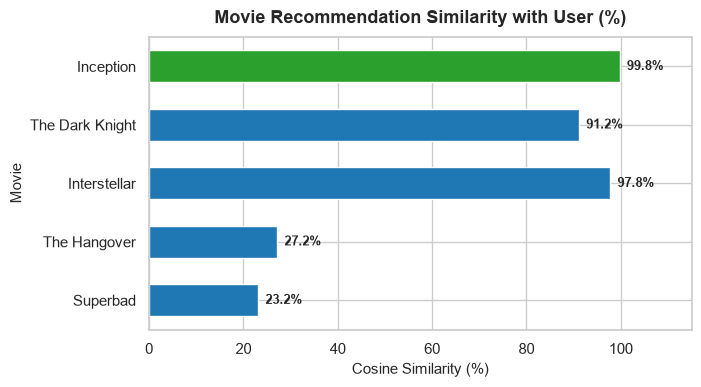

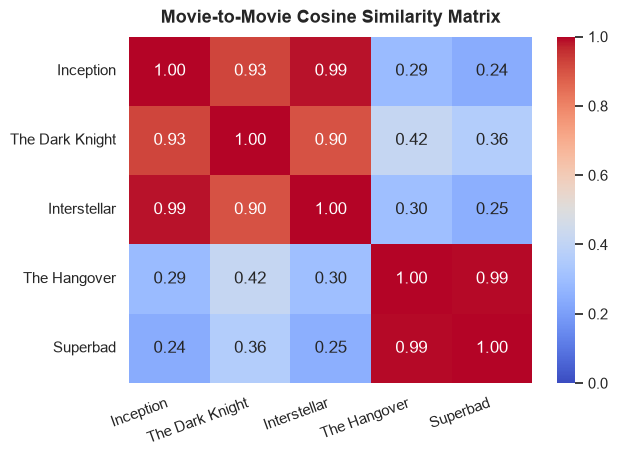

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Cosine Similarity Bar Chart (Matplotlib)
plt.figure(figsize=(7, 3.8))
colors = ['#2ca02c' if i == best_idx else '#1f77b4' for i in range(len(movies))]
bars = plt.barh(movies, cosine_sim * 100, color=colors, height=0.55)
plt.title("Movie Recommendation Similarity with User (%)", fontsize=13, fontweight='bold', pad=10)
plt.xlabel("Cosine Similarity (%)", fontsize=11)
plt.ylabel("Movie", fontsize=11)
plt.xlim(0, 115)
for bar in bars:
    w = bar.get_width()
    plt.text(w + 1.5, bar.get_y() + bar.get_height()/2.0, f"{w:.1f}%", va='center', fontsize=9, fontweight='bold')
plt.gca().invert_yaxis()
plt.show()

# 2. Movie-to-Movie Cosine Similarity Heatmap (Seaborn)
dot_matrix = movie_features @ movie_features.T
norms_col = movie_norms[:, np.newaxis]
sim_matrix = dot_matrix / (norms_col @ norms_col.T)

plt.figure(figsize=(6.5, 4.5))
sns.heatmap(sim_matrix, annot=True, fmt=".2f", cmap="coolwarm", xticklabels=movies, yticklabels=movies, vmin=0, vmax=1)
plt.title("Movie-to-Movie Cosine Similarity Matrix", fontsize=13, fontweight='bold', pad=10)
plt.xticks(rotation=20, ha='right')
plt.show()
